# 07 LSTM Modelling

This notebook trains and evaluates an LSTM model using the current Dublin Bikes feature set and the current `band_30min` target definition.

> This notebook can be memory-intensive. If VS Code becomes unstable, use the optional station subset cell before sequence generation.

In [1]:
import torch
import torch.nn as nn
import time


print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

x = torch.rand(3000, 3000, device=device)
y = torch.rand(3000, 3000, device=device)

torch.cuda.synchronize()
t0 = time.time()
z = x @ y
torch.cuda.synchronize()
t1 = time.time()

print("Result device:", z.device)
print("Elapsed:", t1 - t0, "seconds")

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED) 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

torch: 2.10.0+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU
Using: cuda
Result device: cuda:0
Elapsed: 0.2751896381378174 seconds


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    classification_report,
    roc_auc_score
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report, roc_auc_score


In [3]:
PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 18)


,station_id,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,util_slope,util_vs_mean,time_slot_str,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,13,-0.258819,-0.965926,2,True,0.0,0.0,0.0,0.870968,NaN,0.0,13:00,True,False,1,retail
1,1,2022-04-27 13:30:02,13,-0.382683,-0.923880,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,13:30,True,False,1,retail
2,1,2022-04-27 14:00:02,14,-0.500000,-0.866025,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,14:00,True,False,1,retail
3,1,2022-04-27 14:30:02,14,-0.608761,-0.793353,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,14:30,True,False,1,retail
4,1,2022-04-27 15:00:02,15,-0.707107,-0.707107,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,15:00,True,False,1,retail


## 2. Create targets + lag features

In [4]:

# target variable: utilisation 30 min in the future

df = df.sort_values(["station_id", "last_reported"]).copy()

def get_target(group):
    group = group.sort_values("last_reported").copy()

    # preserve station_id explicitly
    sid = group["station_id"].iloc[0]

    times = group["last_reported"].to_numpy()
    values = group["utilisation"].to_numpy()

    target = np.full(len(group), np.nan)

    for i in range(len(times)):
        t_future = times[i] + np.timedelta64(30, "m")
        idx = np.searchsorted(times, t_future, side="left")
        if idx < len(times):
            target[i] = values[idx]

    group["utilisation_tplus_30"] = target
    group["station_id"] = sid
    return group

parts = []
for _, g in df.groupby("station_id", sort=False):
    parts.append(get_target(g))

df = pd.concat(parts, ignore_index=True)
print(df.shape)
print(df.columns)



  

(13513883, 19)
Index(['station_id', 'last_reported', 'hour_slot', 'hour_sin', 'hour_cos',
       'days_of_week', 'is_weekday', 'roll_mean_30min', 'roll_std_30min',
       'utilisation', 'dock_ratio', 'util_slope', 'util_vs_mean',
       'time_slot_str', 'empty_risk', 'full_risk', 'center_index',
       'area_type_str', 'utilisation_tplus_30'],
      dtype='str')


## 3. Cleaning - dropping missing rows

In [5]:

# Count na per station
na_per_station = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="na_count")
)

# Add total rows per station
counts = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .size()
      .reset_index(name="total_rows")
)

na_stats = na_per_station.merge(counts, on="station_id")

# Percentage of na 
na_stats["na_ratio"] = na_stats["na_count"] / na_stats["total_rows"]

# worst stations with most na in target
na_stats.sort_values("na_ratio", ascending=False).head(10)
problematic = na_stats[na_stats["na_ratio"] > 0.5]
print(problematic)
print(na_stats["na_ratio"].describe())


# Drop rows with na in target
df = df.dropna(subset=["utilisation_tplus_30", "util_slope", "util_vs_mean"])


Empty DataFrame
Columns: [station_id, na_count, total_rows, na_ratio]
Index: []
count    115.000000
mean       0.000033
std        0.000010
min        0.000022
25%        0.000027
50%        0.000033
75%        0.000035
max        0.000126
Name: na_ratio, dtype: float64


 ## 4. Feature list and target definition

In [6]:

# Features

base_features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "util_slope", # trend of utilisation in last 30 min
    "util_vs_mean", # utilisation vs mean of station in last 30 min
    # "station_cluster"   # if added after Maxime's clustering
]

dummy_cols = [c for c in df.columns if c.startswith("area_type_str_") or c.startswith("center_index_")]
features = base_features + dummy_cols
target = "utilisation_tplus_30"

time_col = "last_reported"
group_col = "station_id"

y = df["utilisation_tplus_30"]
print("Target variable:")
print(y.describe())
print("Missing values in target:", y.isna().sum())



# Keep only rows with all required model columns present
df_model = df.dropna(subset=features + [target]).copy()

print("Original shape:", df.shape)
print("Model shape   :", df_model.shape)

print("\nMissing values after cleaning:")
print(df_model[features + [target]].isna().sum().sort_values(ascending=False).head(10))

Target variable:
count    1.350982e+07
mean     3.800239e-01
std      3.047142e-01
min      0.000000e+00
25%      1.000000e-01
50%      3.250000e-01
75%      6.000000e-01
max      1.000000e+00
Name: utilisation_tplus_30, dtype: float64
Missing values in target: 0
Original shape: (13509818, 19)
Model shape   : (13509818, 19)

Missing values after cleaning:
utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
utilisation_tplus_30    0
dtype: int64


## Optional: subset stations for memory stability

In [7]:

# Uncomment this block if sequence creation is too heavy for your machine.
# max_stations = 40
# selected_stations = (
#     df_lstm["station_id"]
#     .drop_duplicates()
#     .sort_values()
#     .iloc[:max_stations]
# )
# df_lstm = df_lstm[df_lstm["station_id"].isin(selected_stations)].copy()
# print("Using subset shape:", df_lstm.shape)


## 7. Train/Val/Test split

In [8]:
df_model[time_col] = pd.to_datetime(df_model[time_col])
df_model = df_model.sort_values([group_col, time_col]).copy()

print(df_model[[group_col, time_col] + features[:3] + [target]].head())

# --- TEST = last 365 days ---
test_cutoff = df_model[time_col].max() - pd.Timedelta(days=365)

# --- VALIDATION = previous 365 days ---
val_cutoff = test_cutoff - pd.Timedelta(days=365)

train_df = df_model[df_model[time_col] < val_cutoff].copy()
val_df   = df_model[(df_model[time_col] >= val_cutoff) & (df_model[time_col] < test_cutoff)].copy()
test_df  = df_model[df_model[time_col] >= test_cutoff].copy()

print("\n--- SPLITS ---")
print("Validation cutoff:", val_cutoff)
print("Test cutoff      :", test_cutoff)

print("\nTrain rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

print("\nTrain range:", train_df[time_col].min(), "to", train_df[time_col].max())
print("Validation range:", val_df[time_col].min(), "to", val_df[time_col].max())
print("Test range:", test_df[time_col].min(), "to", test_df[time_col].max())

   station_id       last_reported  utilisation  roll_std_30min  hour_sin  \
1           1 2022-04-27 13:30:02          0.0             0.0 -0.382683   
2           1 2022-04-27 14:00:02          0.0             0.0 -0.500000   
3           1 2022-04-27 14:30:02          0.0             0.0 -0.608761   
4           1 2022-04-27 15:00:02          0.0             0.0 -0.707107   
5           1 2022-04-27 15:30:02          0.0             0.0 -0.793353   

   utilisation_tplus_30  
1                   0.0  
2                   0.0  
3                   0.0  
4                   0.0  
5                   0.0  

--- SPLITS ---
Validation cutoff: 2023-09-01 23:25:00
Test cutoff      : 2024-08-31 23:25:00

Train rows: 3278460
Validation rows: 3448731
Test rows: 6782627

Train range: 2022-01-01 00:30:03 to 2023-09-01 23:00:02
Validation range: 2023-09-01 23:30:02 to 2024-08-31 23:20:00
Test range: 2024-08-31 23:25:00 to 2025-08-31 23:25:00


## 10. Scaling

Feature scaling was applied for linear models to ensure comparable feature magnitudes, while tree-based models were trained on raw features as they are invariant to scaling.

In [9]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

num_features = [
    "utilisation",
    "roll_std_30min",
    "hour_sin",
    "hour_cos",
    "util_slope",
    "util_vs_mean",
]

scaler = StandardScaler()

# fit on train only
train_scaled = scaler.fit_transform(train_df[num_features].astype("float64"))
val_scaled   = scaler.transform(val_df[num_features].astype("float64"))
test_scaled  = scaler.transform(test_df[num_features].astype("float64"))

# assign back safely, column by column
for i, col in enumerate(num_features):
    train_df[col] = train_scaled[:, i].astype("float32")
    val_df[col]   = val_scaled[:, i].astype("float32")
    test_df[col]  = test_scaled[:, i].astype("float32")

print(train_df[num_features].head())
print(train_df[num_features].dtypes)

   utilisation  roll_std_30min  hour_sin  hour_cos  util_slope  util_vs_mean
1     -1.30775       -0.261244 -0.542146 -1.306872   -0.000138     -0.001764
2     -1.30775       -0.261244 -0.708053 -1.225053   -0.000138     -0.001764
3     -1.30775       -0.261244 -0.861862 -1.122277   -0.000138     -0.001764
4     -1.30775       -0.261244 -1.000941 -1.000303   -0.000138     -0.001764
5     -1.30775       -0.261244 -1.122910 -0.861219   -0.000138     -0.001764
utilisation       float32
roll_std_30min    float32
hour_sin          float32
hour_cos          float32
util_slope        float32
util_vs_mean      float32
dtype: object


## 8. Sequences Building

In [10]:


WINDOW = 6

def make_sequences(data, features, target, group_col="station_id", time_col="last_reported", window=6):
    X_seq = []
    y_seq = []

    for _, g in data.groupby(group_col, sort=False):
        g = g.sort_values(time_col)

        X_vals = g[features].to_numpy(dtype=np.float32)
        y_vals = g[target].to_numpy(dtype=np.float32)

        if len(g) <= window:
            continue

        for i in range(window, len(g)):
            X_seq.append(X_vals[i-window:i])
            y_seq.append(y_vals[i])

    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.float32)

X_train_seq, y_train_seq = make_sequences(
    train_df, features, target, group_col=group_col, time_col=time_col, window=WINDOW
)

X_val_seq, y_val_seq = make_sequences(
    val_df, features, target, group_col=group_col, time_col=time_col, window=WINDOW
)

X_test_seq, y_test_seq = make_sequences(
    test_df, features, target, group_col=group_col, time_col=time_col, window=WINDOW
)

print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)
print("X_val_seq  :", X_val_seq.shape)
print("y_val_seq  :", y_val_seq.shape)
print("X_test_seq :", X_test_seq.shape)
print("y_test_seq :", y_test_seq.shape)

X_train_seq: (3277776, 6, 7)
y_train_seq: (3277776,)
X_val_seq  : (3448047, 6, 7)
y_val_seq  : (3448047,)
X_test_seq : (6781937, 6, 7)
y_test_seq : (6781937,)


## 9. PyTorch datasets and loaders

In [11]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

X_train_t = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_t = torch.tensor(y_train_seq, dtype=torch.float32).unsqueeze(1)

X_val_t = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_t = torch.tensor(y_val_seq, dtype=torch.float32).unsqueeze(1)

X_test_t = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_t = torch.tensor(y_test_seq, dtype=torch.float32).unsqueeze(1)

train_ds = TensorDataset(X_train_t, y_train_t)
val_ds   = TensorDataset(X_val_t, y_val_t)
test_ds  = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False, pin_memory=True)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Using: cuda
Train batches: 12804
Val batches  : 13469
Test batches : 26492


## 10. LSTM model

In [12]:

import torch.nn as nn

class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.2)
        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        return out

model = LSTMRegressor(input_size=X_train_seq.shape[2]).to(device)
print(model)

LSTMRegressor(
  (lstm): LSTM(7, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


## 11. Loss, optimizer, and early stopping setup

In [13]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10
patience = 4

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_state = None
patience_counter = 0

## 12. Training loop with validation and early stopping

In [14]:
import matplotlib.pyplot as plt

for epoch in range(epochs):
    # --- TRAIN ---
    model.train()
    running_train_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * xb.size(0)

    train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    # --- VALIDATION ---
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            preds = model(xb)
            loss = criterion(preds, yb)

            running_val_loss += loss.item() * xb.size(0)

    val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}/{epochs} - train: {train_loss:.6f} - val: {val_loss:.6f}")

    # --- EARLY STOPPING ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = model.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered")
            break

Epoch 1/10 - train: 0.011811 - val: 0.014120
Epoch 2/10 - train: 0.011209 - val: 0.012580
Epoch 3/10 - train: 0.011094 - val: 0.012603
Epoch 4/10 - train: 0.011036 - val: 0.013220
Epoch 5/10 - train: 0.010998 - val: 0.013352
Epoch 6/10 - train: 0.010970 - val: 0.014000
Early stopping triggered


## 13. Restore best model

In [15]:
if best_state is not None:
    model.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Best validation loss: 0.012580268691600569


## 14. Plot training history

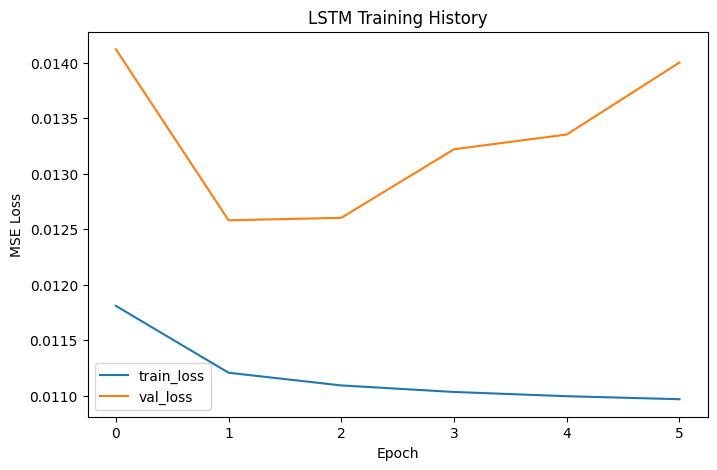

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="train_loss")
plt.plot(val_losses, label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training History")
plt.legend()
plt.show()

## 15.  Prediction on test set

In [17]:

model.eval()
preds_list = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device, non_blocking=True)
        preds = model(xb)
        preds_list.append(preds.cpu())

y_pred_lstm = torch.cat(preds_list).numpy().flatten()
y_pred_lstm = np.clip(y_pred_lstm, 0.0, 1.0)

print("Predictions shape:", y_pred_lstm.shape)
print("First predictions:", y_pred_lstm[:10])

Predictions shape: (6781937,)
First predictions: [0.7396808  0.7470247  0.74652046 0.7449995  0.7451745  0.7457239
 0.7459457  0.7458298  0.746076   0.7462964 ]


## 16. Evaluation - thresholding full/empty

In [18]:


mae = mean_absolute_error(y_test_seq, y_pred_lstm)
rmse = root_mean_squared_error(y_test_seq, y_pred_lstm)

print(f"LSTM MAE: {mae:.4f}")
print(f"LSTM RMSE: {rmse:.4f}")

EMPTY_THRESHOLD = 0.05
FULL_THRESHOLD = 0.95

empty_true = (y_test_seq < EMPTY_THRESHOLD).astype(int)
empty_pred = (y_pred_lstm < EMPTY_THRESHOLD).astype(int)

full_true = (y_test_seq > FULL_THRESHOLD).astype(int)
full_pred = (y_pred_lstm > FULL_THRESHOLD).astype(int)

print("=== LSTM - EMPTY ===")
print(classification_report(empty_true, empty_pred, zero_division=0))

print("=== LSTM - FULL ===")
print(classification_report(full_true, full_pred, zero_division=0))

print("EMPTY ROC AUC:", roc_auc_score(empty_true, -y_pred_lstm))
print("FULL ROC AUC:", roc_auc_score(full_true, y_pred_lstm))



print("Prediction min:", y_pred_lstm.min())
print("Prediction max:", y_pred_lstm.max())
print("Target min:", y_test_seq.min())
print("Target max:", y_test_seq.max())

LSTM MAE: 0.0849
LSTM RMSE: 0.1176
=== LSTM - EMPTY ===
              precision    recall  f1-score   support

           0       0.86      1.00      0.92   5734133
           1       0.96      0.11      0.20   1047804

    accuracy                           0.86   6781937
   macro avg       0.91      0.55      0.56   6781937
weighted avg       0.88      0.86      0.81   6781937

=== LSTM - FULL ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97   6431401
           1       0.32      0.00      0.01    350536

    accuracy                           0.95   6781937
   macro avg       0.63      0.50      0.49   6781937
weighted avg       0.92      0.95      0.92   6781937

EMPTY ROC AUC: 0.9496670026282338
FULL ROC AUC: 0.9651933030463762
Prediction min: 0.0
Prediction max: 1.0
Target min: 0.0
Target max: 1.0


## Plot

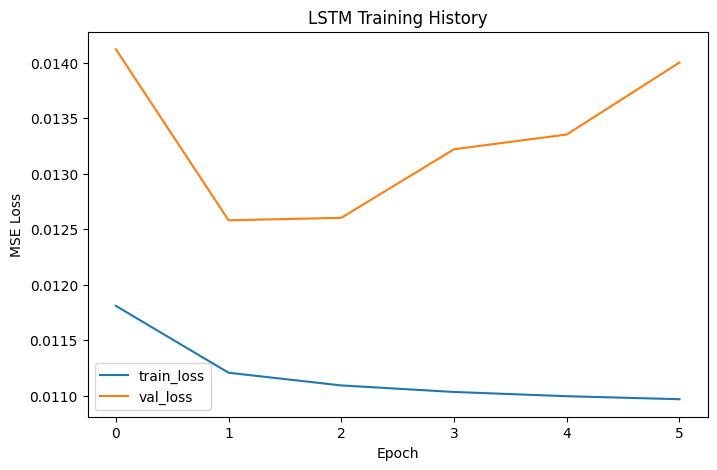

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="train_loss")
plt.plot(val_losses, label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training History")
plt.legend()
plt.show()
